# PyTorch ANN Training for 577-Disease Classification

**Project:** Active Medical Chatbot with ANN-based Diagnosis System

**Framework:** PyTorch (instead of TensorFlow)

**Date:** 2025-10-17

---

## Overview

This notebook trains a PyTorch-based Artificial Neural Network (ANN) for multi-class disease classification:

- **Input:** 377 binary symptom features (sparse representation)
- **Output:** 577 disease classes (common diseases only)
- **Challenge:** Class imbalance (132:1 ratio) and 98.59% sparsity
- **Solution:** Weighted loss function, dropout regularization, batch normalization

**Strategy:** Two-Phase Approach
- **Phase 1 (Current):** Train on 577 common diseases (>10 samples each)
- **Phase 2 (Later):** Add 191 rare diseases when more data is available

---

## PyTorch Architecture

```
Input Layer (377 features)
    ↓
Linear(512) + BatchNorm + ReLU + Dropout(0.3)
    ↓
Linear(256) + BatchNorm + ReLU + Dropout(0.3)
    ↓
Linear(128) + BatchNorm + ReLU + Dropout(0.2)
    ↓
Output Layer (577 classes)
```

**Key Techniques:**
- **Class Weights:** Handle imbalance using sklearn-computed weights
- **Dropout:** Prevent overfitting on sparse data
- **Batch Normalization:** Stabilize training
- **Adam Optimizer:** Adaptive learning rates
- **Learning Rate Scheduling:** ReduceLROnPlateau
- **Early Stopping:** Prevent overtraining

## 1. Environment Setup

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import pickle
from tqdm import tqdm  # Changed from tqdm.notebook to standard tqdm

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, top_k_accuracy_score

# Set random seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.backends.cudnn.deterministic = True

# Display settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
print(f"Python packages loaded successfully!")

PyTorch version: 2.8.0
CUDA available: False
Python packages loaded successfully!


## 2. Configuration

In [2]:
# Define paths
DATA_DIR = Path('../data/processed/common')
MODEL_DIR = Path('../models/pytorch')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration
BATCH_SIZE = 128
EPOCHS = 100
LEARNING_RATE = 0.001
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("="*80)
print("TRAINING CONFIGURATION")
print("="*80)
print(f"Device: {DEVICE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Max epochs: {EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Random seed: {RANDOM_SEED}")

TRAINING CONFIGURATION
Device: cpu
Batch size: 128
Max epochs: 100
Learning rate: 0.001
Random seed: 42


## 3. Load Preprocessed Data

In [3]:
print("Loading preprocessed datasets...")
train_df = pd.read_csv(DATA_DIR / 'train.csv')
val_df = pd.read_csv(DATA_DIR / 'val.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')

print(f" Dataset Sizes:")
print(f"   Training set:   {len(train_df):,} samples")
print(f"   Validation set: {len(val_df):,} samples")
print(f"   Test set:       {len(test_df):,} samples")
print(f"   Total:          {len(train_df) + len(val_df) + len(test_df):,} samples")

# Display first few rows
print(f" Sample data:")
train_df.head()

Loading preprocessed datasets...
 Dataset Sizes:
   Training set:   132,188 samples
   Validation set: 28,327 samples
   Test set:       28,327 samples
   Total:          188,842 samples
 Sample data:


,disease,lo lắng và căng thẳng,trầm cảm,hụt hơi,các triệu chứng trầm cảm hoặc loạn thần,đau ngực dữ dội,chóng mặt,mất ngủ,các chuyển động không tự nguyện bất thường,tức ngực,...,nói lắp hoặc nói ngọng,vấn đề với cực khoái,dị dạng mũi,khối u trên hàm,đau ở mũi,yếu hông,sưng lưng,cứng hoặc căng mắt cá chân,yếu mắt cá chân,yếu cổ
0,đau thắt ngực,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,chu kỳ kinh nguyệt không đều vô căn,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,polyp mũi,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,nhịp nhanh kịch phát trên thất,0,0,0,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,viêm bờ mi,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 4. Prepare Features and Labels

In [4]:
# Separate features and labels
X_train = train_df.drop('disease', axis=1).values.astype('float32')
y_train_labels = train_df['disease'].values

X_val = val_df.drop('disease', axis=1).values.astype('float32')
y_val_labels = val_df['disease'].values

X_test = test_df.drop('disease', axis=1).values.astype('float32')
y_test_labels = test_df['disease'].values

print(f"Feature matrix shapes:")
print(f"   X_train: {X_train.shape}")
print(f"   X_val:   {X_val.shape}")
print(f"   X_test:  {X_test.shape}")

# Encode labels to integers
label_encoder = LabelEncoder()
label_encoder.fit(train_df['disease'])

y_train = label_encoder.transform(y_train_labels)
y_val = label_encoder.transform(y_val_labels)
y_test = label_encoder.transform(y_test_labels)

num_classes = len(label_encoder.classes_)
input_dim = X_train.shape[1]

print(f"  Label encoding:")
print(f"   Number of classes: {num_classes}")
print(f"   Input features: {input_dim}")

# Save label encoder
with open(MODEL_DIR / 'label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)
print(f" Label encoder saved to {MODEL_DIR / 'label_encoder.pkl'}")

Feature matrix shapes:
   X_train: (132188, 377)
   X_val:   (28327, 377)
   X_test:  (28327, 377)
  Label encoding:
   Number of classes: 577
   Input features: 377
 Label encoder saved to ../models/pytorch/label_encoder.pkl


## 5. Load Class Weights

In [5]:
# Load class weights
with open(DATA_DIR / 'class_weights.json', 'r', encoding='utf-8') as f:
    class_weights_dict = json.load(f)

# Convert to PyTorch tensor
class_weights = torch.zeros(num_classes)
for disease_name, weight in class_weights_dict.items():
    class_idx = label_encoder.transform([disease_name])[0]
    class_weights[class_idx] = weight

class_weights = class_weights.to(DEVICE)

print(f" Class weights prepared for {num_classes} classes")
print(f" Weight statistics:")
print(f"   Min weight:    {class_weights.min().item():.3f}")
print(f"   Max weight:    {class_weights.max().item():.3f}")
print(f"   Mean weight:   {class_weights.mean().item():.3f}")
print(f"   Median weight: {class_weights.median().item():.3f}")
print(f"   Weight ratio:  {class_weights.max().item() / class_weights.min().item():.1f}:1")

 Class weights prepared for 577 classes
 Weight statistics:
   Min weight:    0.247
   Max weight:    32.728
   Mean weight:   5.503
   Median weight: 2.010
   Weight ratio:  132.3:1


## 6. Create PyTorch Dataset and DataLoaders

In [ ]:
class DiseaseDataset(Dataset):
    """Custom PyTorch Dataset for disease classification."""
    
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create datasets
train_dataset = DiseaseDataset(X_train, y_train)
val_dataset = DiseaseDataset(X_val, y_val)
test_dataset = DiseaseDataset(X_test, y_test)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f" DataLoaders created:")
print(f"   Train batches: {len(train_loader)}")
print(f"   Val batches:   {len(val_loader)}")
print(f"   Test batches:  {len(test_loader)}")

✅ DataLoaders created:
   Train batches: 1033
   Val batches:   222
   Test batches:  222


## 7. Define PyTorch Model Architecture

In [ ]:
class ANNDiseaseClassifier(nn.Module):
    """
    PyTorch ANN model for 577-disease classification.
    
    Architecture:
    - Input: 377 features
    - Hidden Layer 1: 512 neurons + BatchNorm + ReLU + Dropout(0.3)
    - Hidden Layer 2: 256 neurons + BatchNorm + ReLU + Dropout(0.3)
    - Hidden Layer 3: 128 neurons + BatchNorm + ReLU + Dropout(0.2)
    - Output: 577 classes
    """
    
    def __init__(self, input_dim, num_classes, dropout_rates=(0.3, 0.3, 0.2)):
        super(ANNDiseaseClassifier, self).__init__()
        
        # Layer 1
        self.fc1 = nn.Linear(input_dim, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.dropout1 = nn.Dropout(dropout_rates[0])
        
        # Layer 2
        self.fc2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.dropout2 = nn.Dropout(dropout_rates[1])
        
        # Layer 3
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.dropout3 = nn.Dropout(dropout_rates[2])
        
        # Output layer
        self.fc4 = nn.Linear(128, num_classes)
        
        # Activation
        self.relu = nn.ReLU()
    
    def forward(self, x):
        # Layer 1
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout1(x)
        
        # Layer 2
        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.dropout2(x)
        
        # Layer 3
        x = self.fc3(x)
        x = self.bn3(x)
        x = self.relu(x)
        x = self.dropout3(x)
        
        # Output layer
        x = self.fc4(x)
        return x  # CrossEntropyLoss includes softmax

# Build model
model = ANNDiseaseClassifier(input_dim, num_classes)
model = model.to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f" Model built successfully")
print(f" Model Architecture:")
print(model)
print(f" Parameters:")
print(f"   Total parameters: {total_params:,}")
print(f"   Trainable parameters: {trainable_params:,}")

✅ Model built successfully
📊 Model Architecture:
ANNDiseaseClassifier(
  (fc1): Linear(in_features=377, out_features=512, bias=True)
  (bn1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=256, out_features=128, bias=True)
  (bn3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout3): Dropout(p=0.2, inplace=False)
  (fc4): Linear(in_features=128, out_features=577, bias=True)
  (relu): ReLU()
)
📊 Parameters:
   Total parameters: 433,985
   Trainable parameters: 433,985


## 8. Setup Loss Function and Optimizer

In [ ]:
# Loss function with class weights
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Learning rate scheduler (removed verbose parameter for newer PyTorch)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-7
)

print(" Training setup complete")
print(f"  Configuration:")
print(f"   Optimizer: Adam (lr={LEARNING_RATE})")
print(f"   Loss: CrossEntropyLoss (weighted)")
print(f"   Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)")

✅ Training setup complete
⚙️  Configuration:
   Optimizer: Adam (lr=0.001)
   Loss: CrossEntropyLoss (weighted)
   Scheduler: ReduceLROnPlateau (factor=0.5, patience=5)


## 9. Training and Validation Functions

In [ ]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """Train for one epoch."""
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    for inputs, labels in tqdm(train_loader, desc='Training', leave=False):
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        
        # Predictions
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    
    return epoch_loss, epoch_acc

def validate_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_probs = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in tqdm(val_loader, desc='Validation', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            
            # Predictions and probabilities
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    
    # Calculate top-k accuracies
    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)
    top3_acc = top_k_accuracy_score(all_labels, all_probs, k=3, labels=np.arange(all_probs.shape[1]))
    top5_acc = top_k_accuracy_score(all_labels, all_probs, k=5, labels=np.arange(all_probs.shape[1]))
    
    return epoch_loss, epoch_acc, top3_acc, top5_acc

print(" Training functions defined")

✅ Training functions defined


## 10. Train the Model

In [ ]:
print(" Starting model training...")
print(f"{'='*80}")
print(f"Training Configuration:")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Max epochs: {EPOCHS}")
print(f"   Device: {DEVICE}")
print(f"{'='*80}")

# Training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_top3_acc': [],
    'val_top5_acc': [],
    'lr': []
}

best_val_acc = 0.0
patience_counter = 0
patience_limit = 15

for epoch in range(EPOCHS):
    print(f"Epoch {epoch+1}/{EPOCHS}")
    print("-" * 40)
    
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
    
    # Validate
    val_loss, val_acc, val_top3_acc, val_top5_acc = validate_epoch(model, val_loader, criterion, DEVICE)
    
    # Update scheduler
    scheduler.step(val_loss)
    
    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_top3_acc'].append(val_top3_acc)
    history['val_top5_acc'].append(val_top5_acc)
    history['lr'].append(optimizer.param_groups[0]['lr'])
    
    # Print metrics
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")
    print(f"Val Top-3: {val_top3_acc*100:.2f}% | Val Top-5: {val_top5_acc*100:.2f}%")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.2e}")
    
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_loss': val_loss
        }, MODEL_DIR / 'best_model.pth')
        print(f" Best model saved (Val Acc: {val_acc*100:.2f}%)")
    else:
        patience_counter += 1
    
    # Early stopping
    if patience_counter >= patience_limit:
        print(f"  Early stopping triggered (patience={patience_limit})")
        break

print(f"{'='*80}")
print(" Training completed\!")
print(f"{'='*80}")

🚀 Starting model training...
Training Configuration:
   Batch size: 128
   Max epochs: 100
   Device: cpu
Epoch 1/100
----------------------------------------


Train Loss: 3.0666 | Train Acc: 52.69%
Val Loss: 0.9214 | Val Acc: 77.91%
Val Top-3: 92.01% | Val Top-5: 95.44%
Learning Rate: 1.00e-03
✅ Best model saved (Val Acc: 77.91%)
Epoch 2/100
----------------------------------------


Train Loss: 1.1099 | Train Acc: 70.00%
Val Loss: 0.6007 | Val Acc: 80.59%
Val Top-3: 93.56% | Val Top-5: 96.46%
Learning Rate: 1.00e-03
✅ Best model saved (Val Acc: 80.59%)
Epoch 3/100
----------------------------------------


Train Loss: 0.8771 | Train Acc: 73.06%
Val Loss: 0.5388 | Val Acc: 81.49%
Val Top-3: 93.88% | Val Top-5: 96.77%
Learning Rate: 1.00e-03
✅ Best model saved (Val Acc: 81.49%)
Epoch 4/100
----------------------------------------


Train Loss: 0.8024 | Train Acc: 74.37%
Val Loss: 0.5229 | Val Acc: 81.72%
Val Top-3: 94.03% | Val Top-5: 96.79%
Learning Rate: 1.00e-03
✅ Best model saved (Val Acc: 81.72%)
Epoch 5/100
----------------------------------------


Train Loss: 0.7449 | Train Acc: 75.44%
Val Loss: 0.5002 | Val Acc: 81.75%
Val Top-3: 94.07% | Val Top-5: 96.86%
Learning Rate: 1.00e-03
✅ Best model saved (Val Acc: 81.75%)
Epoch 6/100
----------------------------------------


... (83 outputs left out)

Train Loss: 0.3475 | Train Acc: 83.52%
Val Loss: 0.4217 | Val Acc: 83.68%
Val Top-3: 95.11% | Val Top-5: 97.56%
Learning Rate: 1.95e-06
Epoch 90/100
----------------------------------------


Train Loss: 0.3480 | Train Acc: 83.52%
Val Loss: 0.4239 | Val Acc: 83.68%
Val Top-3: 95.08% | Val Top-5: 97.55%
Learning Rate: 1.95e-06
Epoch 91/100
----------------------------------------


Train Loss: 0.3454 | Train Acc: 83.51%
Val Loss: 0.4223 | Val Acc: 83.70%
Val Top-3: 95.14% | Val Top-5: 97.56%
Learning Rate: 1.95e-06
Epoch 92/100
----------------------------------------


Train Loss: 0.3443 | Train Acc: 83.52%
Val Loss: 0.4246 | Val Acc: 83.70%
Val Top-3: 95.10% | Val Top-5: 97.54%
Learning Rate: 9.77e-07
⚠️  Early stopping triggered (patience=15)
✅ Training completed\!


## 11. Save Final Model

In [ ]:
# Save final model
final_model_path = MODEL_DIR / 'ann_disease_classifier_577.pth'
torch.save({
    'model_state_dict': model.state_dict(),
    'input_dim': input_dim,
    'num_classes': num_classes,
    'architecture': '377 -> 512 -> 256 -> 128 -> 577'
}, final_model_path)
print(f" Final model saved to: {final_model_path}")

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(MODEL_DIR / 'training_history.csv', index=False)
print(f" Training history saved to: {MODEL_DIR / 'training_history.csv'}")

✅ Final model saved to: ../models/pytorch/ann_disease_classifier_577.pth
✅ Training history saved to: ../models/pytorch/training_history.csv


## 12. Visualize Training History

✅ Training curves saved to: ../models/pytorch/training_history_curves.png


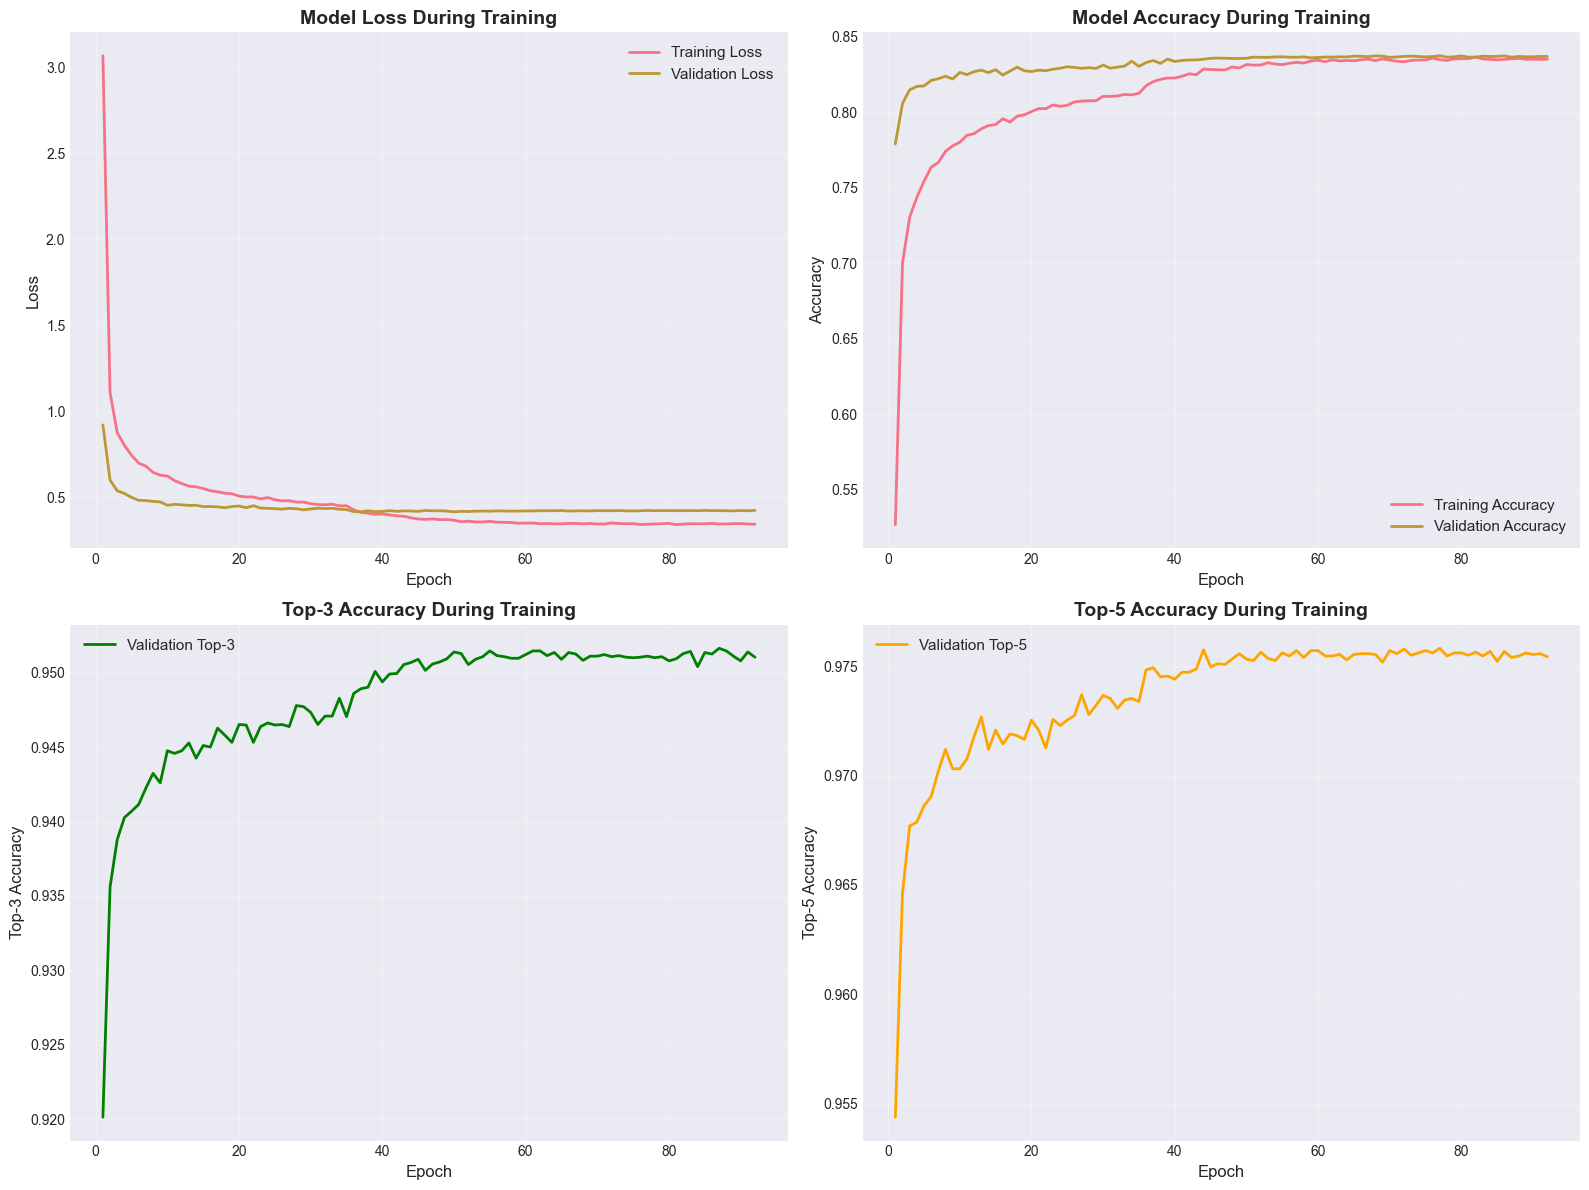

In [ ]:
# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

epochs_range = range(1, len(history['train_loss']) + 1)

# Plot 1: Loss curves
axes[0, 0].plot(epochs_range, history['train_loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(epochs_range, history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_title('Model Loss During Training', fontsize=14, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Accuracy curves
axes[0, 1].plot(epochs_range, history['train_acc'], label='Training Accuracy', linewidth=2)
axes[0, 1].plot(epochs_range, history['val_acc'], label='Validation Accuracy', linewidth=2)
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('Accuracy', fontsize=12)
axes[0, 1].set_title('Model Accuracy During Training', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Top-3 Accuracy
axes[1, 0].plot(epochs_range, history['val_top3_acc'], label='Validation Top-3', linewidth=2, color='green')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('Top-3 Accuracy', fontsize=12)
axes[1, 0].set_title('Top-3 Accuracy During Training', fontsize=14, fontweight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Top-5 Accuracy
axes[1, 1].plot(epochs_range, history['val_top5_acc'], label='Validation Top-5', linewidth=2, color='orange')
axes[1, 1].set_xlabel('Epoch', fontsize=12)
axes[1, 1].set_ylabel('Top-5 Accuracy', fontsize=12)
axes[1, 1].set_title('Top-5 Accuracy During Training', fontsize=14, fontweight='bold')
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = MODEL_DIR / 'training_history_curves.png'
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f" Training curves saved to: {plot_path}")
plt.show()

## 13. Evaluate on Test Set

In [ ]:
print(" Evaluating model on test set...")

# Load best model
checkpoint = torch.load(MODEL_DIR / 'best_model.pth')
model.load_state_dict(checkpoint['model_state_dict'])

# Evaluate
test_loss, test_acc, test_top3_acc, test_top5_acc = validate_epoch(model, test_loader, criterion, DEVICE)

print(f"{'='*80}")
print(f" TEST SET PERFORMANCE")
print(f"{'='*80}")
print(f"Test Loss:         {test_loss:.4f}")
print(f"Test Accuracy:     {test_acc*100:.2f}%")
print(f"Test Top-3 Acc:    {test_top3_acc*100:.2f}%")
print(f"Test Top-5 Acc:    {test_top5_acc*100:.2f}%")
print(f"{'='*80}")

🧪 Evaluating model on test set...


📊 TEST SET PERFORMANCE
Test Loss:         0.4279
Test Accuracy:     83.22%
Test Top-3 Acc:    94.82%
Test Top-5 Acc:    97.50%


## 14. Generate Training Report

In [ ]:
# Generate comprehensive report
best_epoch = np.argmax(history['val_acc'])

training_report = {
    'model_info': {
        'framework': 'PyTorch',
        'architecture': 'ANN (377 -> 512 -> 256 -> 128 -> 577)',
        'input_features': int(input_dim),
        'output_classes': int(num_classes),
        'total_parameters': int(total_params),
        'note': 'Trained on 577 common diseases (>10 samples each). 191 rare diseases excluded.'
    },
    'training_config': {
        'batch_size': BATCH_SIZE,
        'epochs_run': len(history['train_loss']),
        'optimizer': f'Adam (lr={LEARNING_RATE})',
        'loss_function': 'CrossEntropyLoss (weighted)',
        'class_weighted': True,
        'random_seed': RANDOM_SEED,
        'device': str(DEVICE)
    },
    'dataset_info': {
        'training_samples': int(len(X_train)),
        'validation_samples': int(len(X_val)),
        'test_samples': int(len(X_test)),
        'total_samples': int(len(X_train) + len(X_val) + len(X_test)),
        'rare_diseases_excluded': 191
    },
    'best_epoch_metrics': {
        'best_epoch': int(best_epoch + 1),
        'train_loss': float(history['train_loss'][best_epoch]),
        'train_accuracy': float(history['train_acc'][best_epoch]),
        'val_loss': float(history['val_loss'][best_epoch]),
        'val_accuracy': float(history['val_acc'][best_epoch])
    },
    'final_test_metrics': {
        'test_loss': float(test_loss),
        'test_accuracy': float(test_acc),
        'test_top_3_accuracy': float(test_top3_acc),
        'test_top_5_accuracy': float(test_top5_acc)
    },
    'outputs': {
        'model_file': str(final_model_path),
        'best_model_file': str(MODEL_DIR / 'best_model.pth'),
        'label_encoder': str(MODEL_DIR / 'label_encoder.pkl'),
        'training_history': str(MODEL_DIR / 'training_history.csv'),
        'visualizations': str(plot_path)
    }
}

# Save report
report_path = MODEL_DIR / 'training_report.json'
with open(report_path, 'w', encoding='utf-8') as f:
    json.dump(training_report, f, indent=2, ensure_ascii=False)

print(f" Training report saved to: {report_path}")
print(f" Report Summary:")
print(json.dumps(training_report, ensure_ascii=False, indent=2))

✅ Training report saved to: ../models/pytorch/training_report.json
📋 Report Summary:
{
  "model_info": {
    "framework": "PyTorch",
    "architecture": "ANN (377 -> 512 -> 256 -> 128 -> 577)",
    "input_features": 377,
    "output_classes": 577,
    "total_parameters": 433985,
    "note": "Trained on 577 common diseases (>10 samples each). 191 rare diseases excluded."
  },
  "training_config": {
    "batch_size": 128,
    "epochs_run": 92,
    "optimizer": "Adam (lr=0.001)",
    "loss_function": "CrossEntropyLoss (weighted)",
    "class_weighted": true,
    "random_seed": 42,
    "device": "cpu"
  },
  "dataset_info": {
    "training_samples": 132188,
    "validation_samples": 28327,
    "test_samples": 28327,
    "total_samples": 188842,
    "rare_diseases_excluded": 191
  },
  "best_epoch_metrics": {
    "best_epoch": 77,
    "train_loss": 0.34381899141228595,
    "train_accuracy": 0.8348866765515781,
    "val_loss": 0.4243586692814014,
    "val_accuracy": 0.8374695520175098
  },
 